In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import torch
import torch.nn as nn
from transformers import AutoModelForCausalLM ,AutoTokenizer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.cm as cm

In [3]:
tokenizer=AutoTokenizer.from_pretrained("huggyllama/llama-7b")
model=AutoModelForCausalLM.from_pretrained("huggyllama/llama-7b",
                                          torch_dtype=torch.float16,
                                          device_map="auto",
                                          attn_implementation='sdpa',
                                          output_attentions=True)


tokenizer_config.json:   0%|          | 0.00/2.28k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.llama.tokenization_llama_fast.LlamaTokenizerFast'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565 - if you loaded a llama tokenizer from a GGUF file you can ignore this message.


config.json:   0%|          | 0.00/594 [00:00<?, ?B/s]

... (4 outputs left out)

model-00001-of-00002.safetensors:   0%|          | 0.00/9.98G [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/transformers/generation/configuration_utils.py:820: UserWarning: `return_dict_in_generate` is NOT set to `True`, but `output_attentions` is. When `return_dict_in_generate` is not `True`, `output_attentions` is ignored.
  warnings.warn(


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

In [4]:
model.eval()

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 4096, padding_idx=0)
    (layers): ModuleList(
      (0-31): 32 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (up_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=4096, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((4096,), eps=1e-06)
        (post_attention_layernorm): LlamaRMSNorm((4096,), eps=1e-06)
      )
    )
    (norm): LlamaRMSNorm((4096,), eps=1e-06

In [5]:
inputs=tokenizer("Hello,My name is Shreyansh,I study Deep Learninig",return_tensors='pt')

In [6]:
with torch.no_grad():
    outputs=model(**inputs,output_hidden_states=True)

`torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True`. Falling back to eager attention. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


In [7]:
hidden_states=outputs.hidden_states

In [8]:
len(hidden_states)

33

In [9]:
hidden_states[0].shape

torch.Size([1, 18, 4096])

In [10]:
token_idx_my=3
token_idx_i=11
token_idx_d=13
all_hidden_states1=[layer[0][token_idx_my] for layer in hidden_states]
all_hidden_states2=[layer[0][token_idx_i] for layer in hidden_states]
all_hidden_states3=[layer[0][token_idx_d] for layer in hidden_states]

In [11]:
stacked_hidden_states1=torch.stack(all_hidden_states1,dim=0).numpy()
stacked_hidden_states2=torch.stack(all_hidden_states2,dim=0).numpy()
stacked_hidden_states3=torch.stack(all_hidden_states3,dim=0).numpy()
pca=PCA(n_components=2)
projected1 =pca.fit_transform(stacked_hidden_states1)
projected2 =pca.fit_transform(stacked_hidden_states2)
projected3 =pca.fit_transform(stacked_hidden_states3)



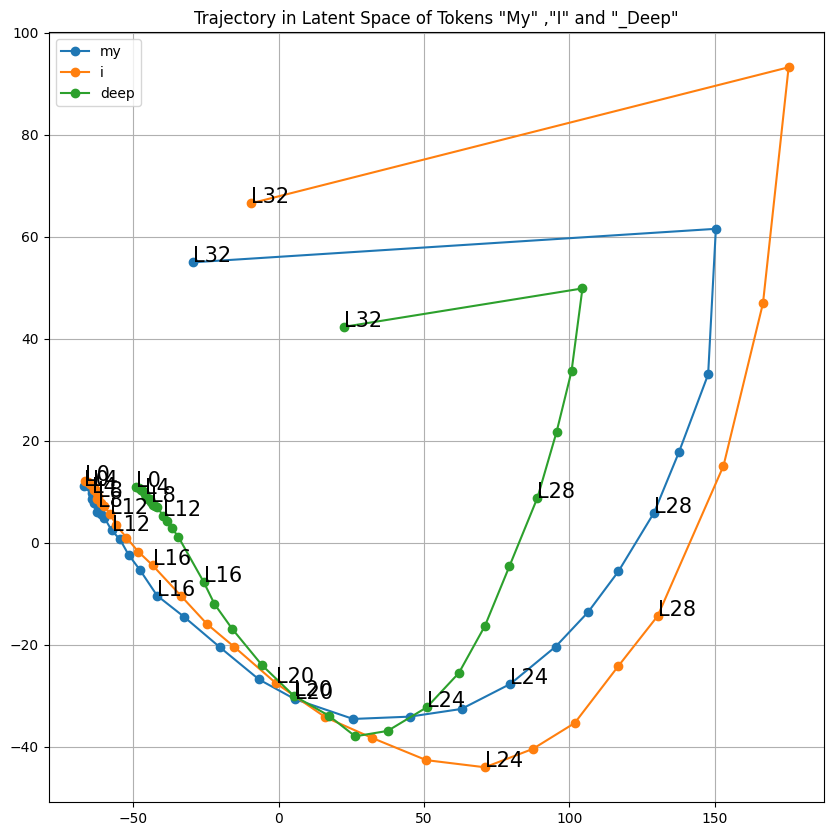

In [12]:
plt.figure(figsize=(10,10))
plt.plot(projected1[:,0],projected1[:,1],marker='o',label='my')
plt.plot(projected2[:,0],projected2[:,1],marker='o',label='i')
plt.plot(projected3[:,0],projected3[:,1],marker='o',label='deep')

for i,(x,y) in enumerate(projected1):
    if i%4==0:
     plt.text(x,y,f"L{i}",fontsize=15)
for i,(x,y) in enumerate(projected2):
    if i%4==0:
     plt.text(x,y,f"L{i}",fontsize=15)
for i,(x,y) in enumerate(projected3):
    if i%4==0:
     plt.text(x,y,f"L{i}",fontsize=15)
plt.title('Trajectory in Latent Space of Tokens "My" ,"I" and "_Deep"')
plt.grid(True)
plt.legend()
plt.show()